In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081127

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp_env
[学号]       20244081127
[机器指纹] a8365f4adeced7e9
[RUN_ID]   20244081127-a8365f4adeced7e9


## 围绕半圆定律

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]  
plt.rcParams["axes.unicode_minus"] = False   

# ========== 任务1：半圆密度函数 wigner_density ==========
def wigner_density(x):
    """
    接收标量/数组x，返回Wigner半圆律密度值
    使用np.sqrt，兼容numpy数组
    """
    x = np.asarray(x)
    result = np.zeros_like(x, dtype=float)
    inside = np.abs(x) <= 2
    result[inside] = (1 / (2 * np.pi)) * np.sqrt(4 - x[inside] ** 2)
    return result


In [3]:
# ========== 任务2：生成Wigner对称矩阵 generate_wigner ==================
def generate_wigner(n):
    """
    生成n×n Wigner对称随机矩阵
    异常：n不是整数抛TypeError；n<=0抛ValueError
    """
    if not isinstance(n, int):
        raise TypeError("n必须为整数")
    if n <= 0:
        raise ValueError("n必须是正整数")
    # 上三角采样 N(0, 1/n)
    mat = np.random.normal(loc=0, scale=1/np.sqrt(n), size=(n, n))
    mat = np.triu(mat)
    # 对称化：Z_ji = Z_ij，对角线不要重复叠加
    mat = mat + mat.T - np.diag(np.diag(mat))
    return mat

In [4]:
# ========== 任务3：获取排序特征值 get_spectrum ==========
def get_spectrum(matrix):
    """
    输入对称矩阵，返回非递减排序的特征值数组
    eigvalsh专门用于实对称矩阵，更快
    """
    eig_vals = np.linalg.eigvalsh(matrix)
    eig_vals.sort()
    return eig_vals

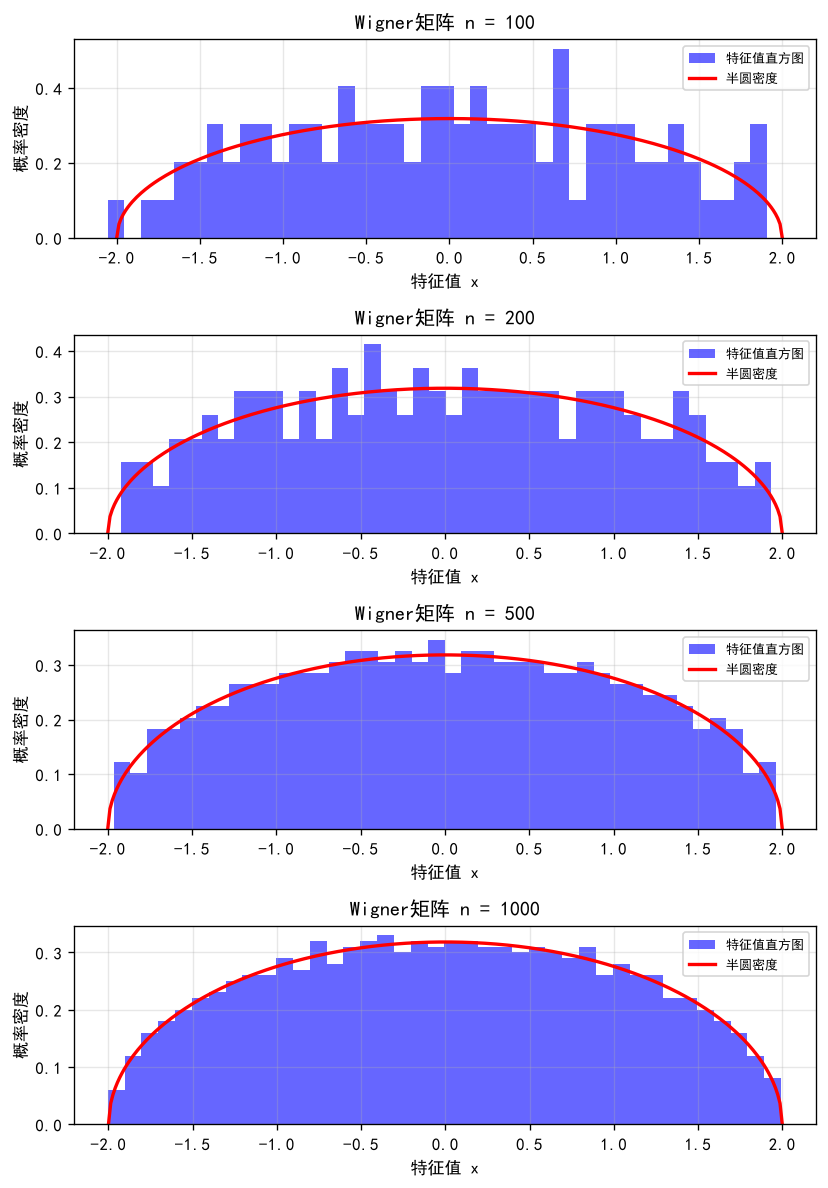

In [5]:
# ========== 任务4：绘图 n=100,200,500,1000 纵向子图 ==========
if __name__ == "__main__":
    np.random.seed(42)  # 固定随机种子
    n_list = [100, 200, 500, 1000]
    fig, axes = plt.subplots(4, 1, figsize=(7, 10), dpi=120)

    for ax, n in zip(axes, n_list):
        w_mat = generate_wigner(n)
        spec = get_spectrum(w_mat)
        # 蓝色标准化直方图
        ax.hist(spec, bins=40, density=True, color="blue", alpha=0.6, label="特征值直方图")
        # 红色半圆密度曲线
        x_plot = np.linspace(-2, 2, 300)
        y_plot = wigner_density(x_plot)
        ax.plot(x_plot, y_plot, c="red", linewidth=2, label="半圆密度")
        ax.set_title(f"Wigner矩阵 n = {n}")
        ax.set_xlabel("特征值 x")
        ax.set_ylabel("概率密度")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

随着阶数 n 增大，直方图越来越贴合红色半圆曲线：

- \(n=100\)：波动比较大，拟合效果一般
- \(n=200\)：波动减小
- \(n=500\)：已经比较接近半圆分布
- \(n=1000\)：直方图和半圆密度曲线吻合很好

结论：**n 大约达到 500 及以上时，半圆密度可以较好拟合特征值分布**。

In [6]:
# KS 检验（Kolmogorov–Smirnov，严格对比）
from scipy.stats import ks_2samp

# 拿n=1000特征值和采样的半圆分布做KS检验
n_test = 1000
Z_test = generate_wigner(n_test)
eig_test = get_spectrum(Z_test)

# 从半圆分布采样（拒绝采样）
def sample_semicircle(N):
    samples = []
    while len(samples) < N:
        x = np.random.uniform(-2,2)
        u = np.random.uniform(0, 1/(2*np.pi)*2)
        if u < wigner_density(x):
            samples.append(x)
    return np.array(samples)
semi_sample = sample_semicircle(n_test)
stat, pval = ks_2samp(eig_test, semi_sample)

print(f"KS统计量={stat:.4f}, p值={pval:.4f}")

KS统计量=0.0240, p值=0.9358


原假设 $H_0$：Wigner 矩阵特征值分布与半圆律分布是同一个分布  
显著性水平一般取 $α=0.05$   
$p=0.9358 \gg 0.05$，不能拒绝原假设  
KS 统计量 0.0240 很小，代表两个经验累积分布函数之间最大差距很小  

结论：在 $n=1000$ 时，KS 检验支持特征值分布和半圆律分布一致，拟合效果很好。

## Conway 的生命游戏

In [7]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]   
plt.rcParams["axes.unicode_minus"] = False   

# ========== 任务1：is_valid_board ==========
def is_valid_board(board):
    """
    判断是否为合法生命游戏棋盘：二维数组，元素只能是0或1
    """
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    # 所有元素只能是0或者1
    return np.all(np.isin(board, [0, 1]))

In [8]:
# ========== 任务2：gol_step 一步演化，环绕边界 ==========
def gol_step(board):
    """
    输入棋盘，返回下一步棋盘，环绕边界（周期边界）
    先校验棋盘，非法抛出异常；更新全部基于原棋盘
    """
    if not is_valid_board(board):
        raise ValueError("输入不是合法的生命游戏棋盘")
    m, n = board.shape
    # 环绕边界求邻居和：np.roll 实现周期平移
    neighbor_sum = np.zeros_like(board, dtype=int)
    # 8个方向：上下左右 + 四个对角
    dirs = [(-1,-1), (-1,0), (-1,1),
            (0,-1),          (0,1),
            (1,-1),  (1,0), (1,1)]
    for di, dj in dirs:
        neighbor_sum += np.roll(np.roll(board, di, axis=0), dj, axis=1)

    next_board = np.zeros_like(board)
    # 规则
    # 活细胞=1：邻居2或3存活；<2 或>3死亡
    # 死细胞=0：邻居恰好3复活
    alive = board == 1
    dead = board == 0
    next_board[alive & ((neighbor_sum == 2) | (neighbor_sum == 3))] = 1
    next_board[dead & (neighbor_sum == 3)] = 1
    return next_board

In [9]:
# ========== 任务3：draw_gol_board 绘图 ==========
def draw_gol_board(board):
    """
    绘制棋盘：活细胞黑色，死细胞白色
    """
    plt.figure()
    # cmap='gray'：0白，1黑
    plt.imshow(board, cmap="gray", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

棋盘是否合法： True
第 0 代：


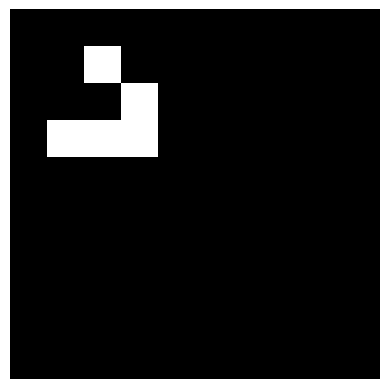

第 1 代：


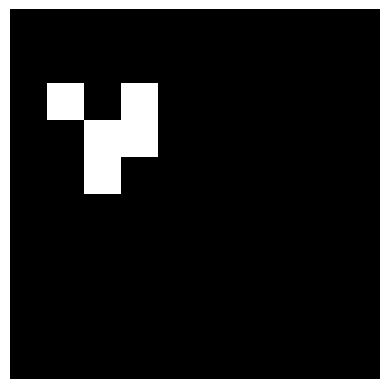

第 2 代：


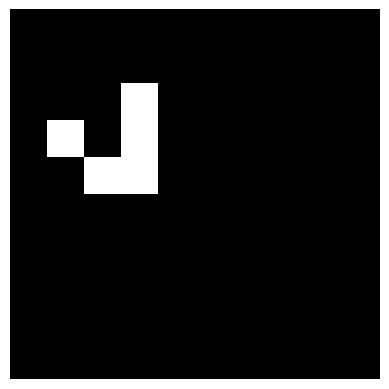

第 3 代：


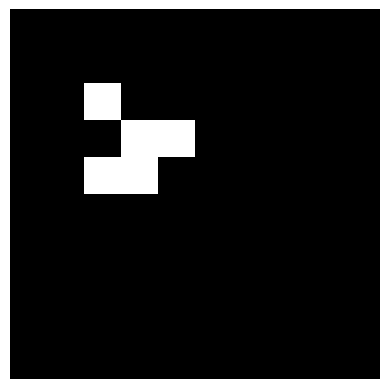

In [10]:
if __name__ == "__main__":
    # 滑翔机测试
    glider = np.array([
        [0, 1, 0],
        [0, 0, 1],
        [1, 1, 1]
    ])
    board = np.zeros((10,10), dtype=int)
    board[1:4, 1:4] = glider
    print("棋盘是否合法：", is_valid_board(board))
    for step in range(4):
        print(f"第 {step} 代：")
        draw_gol_board(board)
        board = gol_step(board)

滑翔机（glider）是康威生命游戏里经典的平移图案，会沿着棋盘对角线持续移动。  
第 0 代是初始构型；每调用一次 `gol_step()`，就按照生命游戏规则计算下一代细胞状态。  
循环一共输出 0、1、2、3 代，观察滑翔机随时间推移向右下方移动的演化效果。  

## 使用 pandas DataFrame

In [11]:
import pandas as pd

# ========== 任务1：读取iris.csv，查看基本信息 ==========
df = pd.read_csv("iris.csv")

print("数据点总数（行数）：", len(df))

print("\n每列数据类型：")
print(df.dtypes)

print("\n列名：")
print(df.columns.tolist())

print("\n花卉种类数量：", df["Species"].nunique())

print("\n花卉种类及数量：")
print(df["Species"].value_counts())

数据点总数（行数）： 150

每列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

列名：
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

花卉种类数量： 3

花卉种类及数量：
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [12]:
# ========== 任务2：修改第35、38行（0索引：34、37） ==========
# 第35行：4.9,3.1,1.5,0.2,"Iris-setosa"
df.loc[34] = [35, 4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
# 第38行：4.9,3.6,1.4,0.1,"Iris-setosa"
df.loc[37] = [38, 4.9, 3.6, 1.4, 0.1, "Iris-setosa"]
# 打印修改后的数据
df.loc[[34, 37]]

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,35,4.9,3.1,1.5,0.2,Iris-setosa
37,38,4.9,3.6,1.4,0.1,Iris-setosa


In [13]:
# ========== 任务3：新增 Petal.Ratio、Sepal.Ratio ==========
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

In [14]:
# ========== 任务4：保存文件 ==========
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv")
# 打印前5行
df.head()

已保存 iris_corrected.csv


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889


In [15]:
# ========== 任务5：分组聚合，均值、中位数、最小、最大、标准差 ==========
agg_result = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
# 打印结果
agg_result

Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
Species                                                                       
Iris-setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
Iris-versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
Iris-virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                         
                   median       min       max       std  
Species                                                  
Iris-setosa      1.463063  1.268293  1.956522  0.118750  
Iris-versicolor  2.161290  1.764706  2.818182  0.228658  
Iris-virginica   2.169540  1.823529  2.961538  0.246992